# 09 · Text → Tokens → Vectors: BPE, WordPiece, embeddings, positions

**Handout:** *Text → Tokens → Vectors* · **Notes:** `../notes/09_text_tokens_vectors.md`

How a Transformer turns raw text into an ordered sequence of vectors, in three stages:

**"playing!" → tokens ["play", "##ing", "!"] → IDs [27, 91, 8] → rows of an embedding table → + position vectors → ordered input**

In this notebook you will:
1. **Build a BPE trainer from scratch** (the handout's take-home challenge) and reproduce its worked example merge by merge.
2. Compute the **WordPiece** association score and write the **greedy longest-match** segmenter, then solve the handout's exercises in code.
3. Run the **real BERT WordPiece tokenizer** (its actual 30,522-token vocabulary) on the handout's practical samples.
4. Verify that an **embedding layer** is a lookup table (= one-hot × matrix), compute its parameters and memory, and see that **only the used rows get gradients**.
5. Build **sinusoidal positional encodings** and prove that attention **without positions can't tell "dog bites man" from "man bites dog"**.

Runs in under a minute. The only download is BERT's vocabulary file (about 230 KB).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from collections import Counter
torch.manual_seed(0)

## 1 · Why subwords? The trade-off in one table

| Unit | Vocabulary size | Sequence length | Advantage | Problem |
|---|---|---|---|---|
| whole words | very large | short | natural units | unknown words, typos, rare forms |
| characters / bytes | very small | long | any string representable | more positions → more computation |
| **subwords** | medium | medium | reusable pieces, few unknowns | segmentation quality varies by domain/language |

Two costs pull in opposite directions:
- **embedding parameters = V × d**, so a bigger vocabulary means a bigger table;
- **attention work per layer ∝ n²·d**, so more tokens make it quadratically slower.

In [2]:
for n in [100, 200, 400]:
    print(f"sequence length {n:>3} tokens -> relative attention work {(n / 100) ** 2:>4.0f}x")

sequence length 100 tokens -> relative attention work    1x
sequence length 200 tokens -> relative attention work    4x
sequence length 400 tokens -> relative attention work   16x


Doubling the number of tokens makes the n² part of attention about **4×** more work. That's why a tokenizer that splits text into fewer, well-chosen pieces matters for cost and speed.

## 2 · Byte Pair Encoding (BPE), from scratch

**Training rule:** start from characters, then repeatedly **merge the most frequent adjacent pair** (counts weighted by word frequency), recording each merge. It is a greedy **compression** procedure, not a dictionary of meaningful morphemes.

The handout's corpus: `low` ×5, `lower` ×2, `newest` ×6, `widest` ×3, with `</w>` marking the end of a word.

In [3]:
corpus = [(["l", "o", "w", "</w>"], 5),
          (["l", "o", "w", "e", "r", "</w>"], 2),
          (["n", "e", "w", "e", "s", "t", "</w>"], 6),
          (["w", "i", "d", "e", "s", "t", "</w>"], 3)]

def pair_counts(corpus):                     # the handout's starter code
    counts = {}
    for symbols, frequency in corpus:
        for pair in zip(symbols, symbols[1:]):
            counts[pair] = counts.get(pair, 0) + frequency
    return counts

def merge_word(symbols, pair):
    out, i = [], 0
    while i < len(symbols):
        if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == pair:
            out.append(symbols[i] + symbols[i + 1]); i += 2      # glue the pair into one symbol
        else:
            out.append(symbols[i]); i += 1
    return out

counts = pair_counts(corpus)
for pair, c in sorted(counts.items(), key=lambda kv: -kv[1])[:8]:
    print(pair, c)

('e', 's') 9
('s', 't') 9
('t', '</w>') 9
('w', 'e') 8
('l', 'o') 7
('o', 'w') 7
('n', 'e') 6
('e', 'w') 6


This matches the handout: **(e,s), (s,t) and (t,</w>) tie at 9**, (w,e) has 8, (l,o) has 7. A real implementation needs a **deterministic tie-break**. Python's `max` keeps the **first** pair it finds with the highest count, which here is (e,s), the same choice the handout makes.

In [4]:
def train_bpe(corpus, K, verbose=True):
    corpus = [(list(s), f) for s, f in corpus]
    merges = []
    for k in range(K):
        counts = pair_counts(corpus)
        if not counts:
            break
        best = max(counts, key=counts.get)                      # first pair with the maximum count
        corpus = [(merge_word(s, best), f) for s, f in corpus]
        merges.append(best)
        if verbose:
            words = "   ".join(" ".join(s) + f"(x{f})" for s, f in corpus)
            print(f"merge {k + 1:>2}: {best[0]!r:>6} + {best[1]!r:<6} (count {counts[best]:>2}) -> {words}")
    return merges, corpus

merges, final = train_bpe(corpus, K=10)

merge  1:    'e' + 's'    (count  9) -> l o w </w>(x5)   l o w e r </w>(x2)   n e w es t </w>(x6)   w i d es t </w>(x3)
merge  2:   'es' + 't'    (count  9) -> l o w </w>(x5)   l o w e r </w>(x2)   n e w est </w>(x6)   w i d est </w>(x3)
merge  3:  'est' + '</w>' (count  9) -> l o w </w>(x5)   l o w e r </w>(x2)   n e w est</w>(x6)   w i d est</w>(x3)
merge  4:    'l' + 'o'    (count  7) -> lo w </w>(x5)   lo w e r </w>(x2)   n e w est</w>(x6)   w i d est</w>(x3)
merge  5:   'lo' + 'w'    (count  7) -> low </w>(x5)   low e r </w>(x2)   n e w est</w>(x6)   w i d est</w>(x3)
merge  6:    'n' + 'e'    (count  6) -> low </w>(x5)   low e r </w>(x2)   ne w est</w>(x6)   w i d est</w>(x3)
merge  7:   'ne' + 'w'    (count  6) -> low </w>(x5)   low e r </w>(x2)   new est</w>(x6)   w i d est</w>(x3)
merge  8:  'new' + 'est</w>' (count  6) -> low </w>(x5)   low e r </w>(x2)   newest</w>(x6)   w i d est</w>(x3)
merge  9:  'low' + '</w>' (count  5) -> low</w>(x5)   low e r </w>(x2)   newest</w>(x6)

Exactly the handout's story: **merge 1 (e,s) → es**, **merge 2 (es,t) → est**, then the ending `est</w>`. Then (l,o) → lo and (lo,w) → low, so the frequent word **low** becomes a single token, and so does **newest** (merge 8). **widest** is still in pieces after 10 merges, because it is less frequent. That answers **Exercise 2**: after the first two merges, (l,o) still occurs 7 times (low ×5 + lower ×2), and merging it creates `lo`, so `(lo, w)` (also 7) can form `low`.

### Applying learned merges to new words
Encoding a new word = split it into characters, then **apply the stored merges in the order they were learned**.

In [5]:
def bpe_encode(word, merges):
    symbols = list(word) + ["</w>"]
    for pair in merges:
        symbols = merge_word(symbols, pair)
    return symbols

for w in ["lowest", "newer", "wider", "slow", "low"]:
    print(f"{w:>7} -> {bpe_encode(w, merges)}")

 lowest -> ['low', 'est</w>']
  newer -> ['new', 'e', 'r', '</w>']
  wider -> ['wi', 'd', 'e', 'r', '</w>']
   slow -> ['s', 'low</w>']
    low -> ['low</w>']


The unseen word **lowest** reuses learned pieces (`low` + `est</w>`). Nothing is ever "unknown": the worst case falls back to single characters.

## 3 · WordPiece

### 3a · The training score: association, not just frequency
Classroom score: **score(a, b) = count(ab) / (count(a) × count(b))**. Common pieces are penalised by the denominator.

In [6]:
score = lambda c_ab, c_a, c_b: c_ab / (c_a * c_b)
print(f"pair xy: 10 / (100 x 20) = {score(10, 100, 20):.3f}")
print(f"pair ab:  6 / (10 x 10)  = {score(6, 10, 10):.3f}  <- WordPiece prefers ab, although xy is more frequent")

pair xy: 10 / (100 x 20) = 0.005
pair ab:  6 / (10 x 10)  = 0.060  <- WordPiece prefers ab, although xy is more frequent


### 3b · Encoding: greedy longest match, with `##` for continuation pieces

In [7]:
def wordpiece(word, vocab, unk="[UNK]"):
    pieces, start = [], 0
    while start < len(word):
        end, found = len(word), None
        while start < end:                                  # try the LONGEST piece first
            piece = word[start:end] if start == 0 else "##" + word[start:end]
            if piece in vocab:
                found = piece; break
            end -= 1
        if found is None:
            return [unk]                                    # classic WordPiece gives up on the whole word
        pieces.append(found); start = end
    return pieces

vocab_a = {"play", "##ing", "##er", "un", "##able", "able"}
for w in ["playing", "player", "unable"]:
    print(f"{w:>9} -> {wordpiece(w, vocab_a)}")

print("\nExercise 3 vocabulary: read, ##ing, ##er, un, ##read, ##able")
vocab_b = {"read", "##ing", "##er", "un", "##read", "##able"}
for w in ["reader", "reading", "unreadable"]:
    print(f"{w:>11} -> {wordpiece(w, vocab_b)}")
print("without ##read:", wordpiece("unreadable", vocab_b - {"##read"}))

  playing -> ['play', '##ing']
   player -> ['play', '##er']
   unable -> ['un', '##able']

Exercise 3 vocabulary: read, ##ing, ##er, un, ##read, ##able
     reader -> ['read', '##er']
    reading -> ['read', '##ing']
 unreadable -> ['un', '##read', '##able']
without ##read: ['[UNK]']


**Exercise 3 answered by running it:** all three words segment successfully with the listed vocabulary (`unreadable → un + ##read + ##able`). The handout's question says "which item *may* fail", and its answer key reaches the same conclusion: it succeeds here. It **would** fail (`[UNK]`) without `##read`, because after `un` the rest of the word must be matched with **continuation** pieces, and the standalone `read` doesn't count. The last line proves it.

## 4 · The real thing: BERT's WordPiece tokenizer

The handout's practical uses `bert-base-uncased`. We load its actual vocabulary file (30,522 tokens): first from Hugging Face (the normal route), and if that fails, from a GitHub mirror of the same file. Then we run the fast `tokenizers` library, the engine inside Hugging Face's `AutoTokenizer`.

In [8]:
import os, urllib.request
os.makedirs("data", exist_ok=True)
VOCAB = "data/bert-base-uncased-vocab.txt"
if not os.path.exists(VOCAB):
    for url in ["https://huggingface.co/bert-base-uncased/resolve/main/vocab.txt",
                "https://raw.githubusercontent.com/microsoft/SDNet/master/bert_vocab_files/bert-base-uncased-vocab.txt"]:
        try:
            urllib.request.urlretrieve(url, VOCAB); print("vocabulary from", url.split("/")[2]); break
        except Exception as e:
            print("failed:", url.split("/")[2], type(e).__name__)
vocab_lines = open(VOCAB, encoding="utf-8").read().splitlines()
print("vocabulary size:", len(vocab_lines), "| first special tokens:", vocab_lines[0], vocab_lines[100:104])

from tokenizers import BertWordPieceTokenizer     # pip install tokenizers  (Hugging Face's fast tokenizer library)
bert = BertWordPieceTokenizer(VOCAB, lowercase=True)
samples = ["Tokenization is unbelievably useful.",
           "Tokenizashun is useful.",                       # deliberate typo
           "vector<vector<int>> values;",                   # source code
           "Thiruvananthapuram costs ₹1,23,456.",           # rare place name + Indian number format
           "playing player unplayable",
           "Tokenization is incredibly useful.",            # English ...
           "La tokenización es increíblemente útil."]       # ... and the same sentence in Spanish
for text in samples:
    enc = bert.encode(text)
    print(f"\n{text}\n  {len(enc.ids):>2} tokens: {enc.tokens}")

vocabulary size: 30522 | first special tokens: [PAD] ['[UNK]', '[CLS]', '[SEP]', '[MASK]']

Tokenization is unbelievably useful.
  12 tokens: ['[CLS]', 'token', '##ization', 'is', 'un', '##bel', '##ie', '##va', '##bly', 'useful', '.', '[SEP]']

Tokenizashun is useful.
   9 tokens: ['[CLS]', 'token', '##iza', '##shu', '##n', 'is', 'useful', '.', '[SEP]']

vector<vector<int>> values;
  11 tokens: ['[CLS]', 'vector', '<', 'vector', '<', 'int', '>', '>', 'values', ';', '[SEP]']

Thiruvananthapuram costs ₹1,23,456.
  18 tokens: ['[CLS]', 'th', '##ir', '##u', '##vana', '##nt', '##ha', '##puram', 'costs', '₹', '##1', ',', '23', ',', '45', '##6', '.', '[SEP]']

playing player unplayable
   7 tokens: ['[CLS]', 'playing', 'player', 'un', '##play', '##able', '[SEP]']

Tokenization is incredibly useful.
   8 tokens: ['[CLS]', 'token', '##ization', 'is', 'incredibly', 'useful', '.', '[SEP]']

La tokenización es increíblemente útil.
  15 tokens: ['[CLS]', 'la', 'token', '##iza', '##cion', 'es', 'inc

**Observation table** (the handout's practical, filled in from the run above):
- **Common sentence:** "tokenization" → `token ##ization`, and even "unbelievably" splits into **5** pieces. Frequent-looking words aren't always single tokens.
- **Typo:** "Tokenizashun" doesn't become `[UNK]`. It breaks into smaller pieces (`token ##iza ##shu ##n`), so subwords handle typos gracefully, at the cost of more tokens.
- **Source code:** every symbol becomes its own token, and identifiers are kept when they are English words.
- **Place name + number:** the rare Indian place name shatters into **7** pieces, and "₹1,23,456" (Indian digit grouping) becomes 7 tokens. A 3-word sentence cost 16 tokens plus the 2 special tokens: high **token fertility** for text outside the tokenizer's main training domain.
- **English vs Spanish, same meaning:** "Tokenization is incredibly useful." needs 6 tokens without the specials, while the Spanish sentence needs 13, more than **twice** as many, because the vocabulary was built mostly from English text. This is the handout's **cost and fairness** question: users of some languages pay more tokens (money, context window, speed) for the same meaning.
- `[CLS]` and `[SEP]` are special tokens BERT adds at the start and end.

## 5 · Embedding layers: a trainable lookup table

Token IDs are just names (ID 27 is not "bigger" than ID 8). The embedding matrix **E** has shape **V × d**: one learnable row per token. Embedding a sequence of n IDs gives an **n × d** matrix.

In [9]:
embedding = nn.Embedding(num_embeddings=100, embedding_dim=4)        # the handout's code
ids = torch.tensor([[27, 91, 8]])                                      # (batch=1, sequence=3)
x = embedding(ids)
print("E shape:", tuple(embedding.weight.shape), "| output shape:", tuple(x.shape))
print("x[0, 0] is exactly row 27 of E:", torch.equal(x[0, 0], embedding.weight[27]))
one_hot = nn.functional.one_hot(ids, num_classes=100).float()
print("lookup == one-hot @ E:", torch.allclose(x, one_hot @ embedding.weight))
print(f"one-hot route: builds {one_hot.numel()} numbers ({int(one_hot.sum())} non-zero) and multiplies by the whole table -> lookup is far cheaper")

E shape: (100, 4) | output shape: (1, 3, 4)
x[0, 0] is exactly row 27 of E: True
lookup == one-hot @ E: True
one-hot route: builds 300 numbers (3 non-zero) and multiplies by the whole table -> lookup is far cheaper


### Parameters and memory (handout example and Exercise 4)

In [10]:
def table(V, d):
    params = V * d
    return params, params * 4 / 1e6, params * 2 / 1e6        # fp32 MB, fp16 MB (decimal)
for name, V, d in [("handout example", 30_000, 768), ("Exercise 4", 50_000, 512), ("real bert-base-uncased", 30_522, 768)]:
    p, mb32, mb16 = table(V, d)
    print(f"{name:>22}: E is {V:,} x {d} = {p:,} parameters -> fp32 {mb32:.2f} MB, fp16 {mb16:.2f} MB")
B, n = 8, 128
print(f"Exercise 4: a batch of token IDs of shape ({B}, {n}) becomes an embedded tensor of shape ({B}, {n}, 512)")
print(f"handout example in MiB: {30_000 * 768 * 4 / 2**20:.1f} MiB")

       handout example: E is 30,000 x 768 = 23,040,000 parameters -> fp32 92.16 MB, fp16 46.08 MB
            Exercise 4: E is 50,000 x 512 = 25,600,000 parameters -> fp32 102.40 MB, fp16 51.20 MB
real bert-base-uncased: E is 30,522 x 768 = 23,440,896 parameters -> fp32 93.76 MB, fp16 46.88 MB
Exercise 4: a batch of token IDs of shape (8, 128) becomes an embedded tensor of shape (8, 128, 512)
handout example in MiB: 87.9 MiB


### Only the rows that were used get gradients
IDs `[4, 9, 4]`: rows 4 and 9 receive gradient, and **row 4 accumulates two contributions** (it appeared twice).

In [11]:
emb = nn.Embedding(12, 3)
out = emb(torch.tensor([4, 9, 4]))
out.sum().backward()                                   # a toy loss: every output element counts 1
rows_with_grad = (emb.weight.grad.abs().sum(1) > 0).nonzero().ravel().tolist()
print("rows with non-zero gradient:", rows_with_grad)
print("gradient of row 4:", emb.weight.grad[4].tolist(), " (two positions -> 2 per element)")
print("gradient of row 9:", emb.weight.grad[9].tolist(), " (one position  -> 1 per element)")

rows with non-zero gradient: [4, 9]
gradient of row 4: [2.0, 2.0, 2.0]  (two positions -> 2 per element)
gradient of row 9: [1.0, 1.0, 1.0]  (one position  -> 1 per element)


That's the handout's **∂L/∂E[4] = ∂L/∂x₁ + ∂L/∂x₃** in action. It's also why rare tokens learn slowly: their rows are only updated when they appear.

**Static vs contextual:** row "bank" of E is the same in "river bank" and "bank loan". The **later Transformer layers** produce different, contextual vectors (see the CV course's attention notebook for the "bank" example).

## 6 · Positions: why attention needs them

### 6a · Proof: content-only attention ignores word order

In [12]:
torch.manual_seed(0)
d = 8
words = {"dog": 0, "bites": 1, "man": 2}
E = nn.Embedding(3, d)
attn = nn.MultiheadAttention(embed_dim=d, num_heads=1, batch_first=True)

def encode(sentence, pos=None):
    x = E(torch.tensor([[words[w] for w in sentence.split()]]))
    return x if pos is None else x + pos[: x.shape[1]]

with torch.no_grad():
    for label, pos in [("WITHOUT positions", None), ("WITH positions", torch.randn(3, d))]:
        a, b = encode("dog bites man", pos), encode("man bites dog", pos)
        out_a, _ = attn(a, a, a); out_b, _ = attn(b, b, b)
        # compare the output vector for each WORD (dog, bites, man) across the two sentences
        same_per_word = torch.allclose(out_a[0, [0, 1, 2]], out_b[0, [2, 1, 0]], atol=1e-6)
        print(f"{label}: outputs for each word identical in both sentences? {same_per_word}   "
              f"| sentence summaries (mean) identical? {torch.allclose(out_a.mean(1), out_b.mean(1), atol=1e-6)}")

WITHOUT positions: outputs for each word identical in both sentences? True   | sentence summaries (mean) identical? True
WITH positions: outputs for each word identical in both sentences? False   | sentence summaries (mean) identical? False


**Without positions**, each word gets exactly the same output vector whether the sentence is "dog bites man" or "man bites dog". The outputs are just **reordered** with the input (**permutation equivariance**), and any order-free summary is identical. The model literally can't tell who bit whom. **With position vectors added**, the outputs differ.

### 6b · Sinusoidal positional encodings
**PE(pos, 2i) = sin(pos / 10000^(2i/d))**, **PE(pos, 2i+1) = cos(pos / 10000^(2i/d))**

handout example, d = 4, position 1: [0.84147 0.5403  0.01    0.99995]  (expected [0.8415, 0.5403, 0.0100, 0.99995])


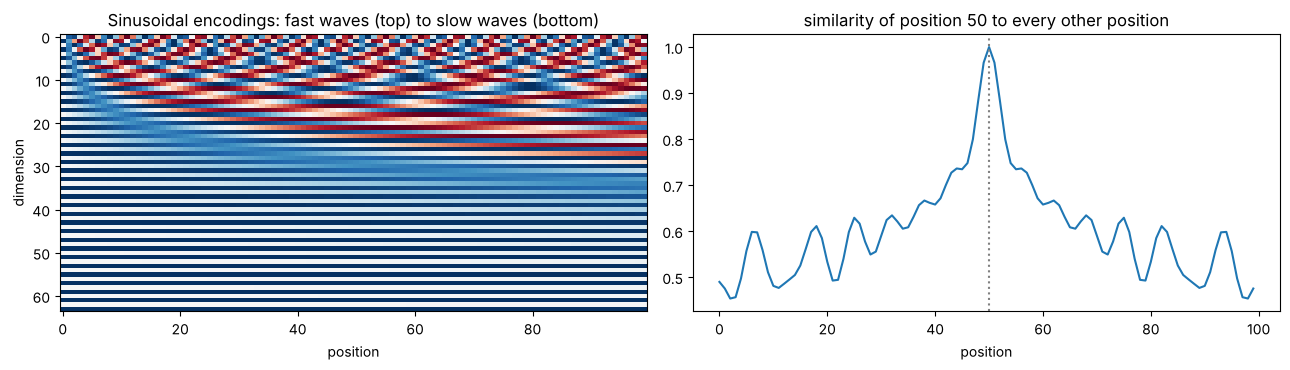

In [13]:
def sinusoidal(max_len, d):
    pe = np.zeros((max_len, d))
    pos = np.arange(max_len)[:, None]
    i = np.arange(0, d, 2)[None, :]
    pe[:, 0::2] = np.sin(pos / 10000 ** (i / d))
    pe[:, 1::2] = np.cos(pos / 10000 ** (i / d))
    return pe

print("handout example, d = 4, position 1:", sinusoidal(2, 4)[1].round(5), " (expected [0.8415, 0.5403, 0.0100, 0.99995])")
pe = sinusoidal(100, 64)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].imshow(pe.T, aspect="auto", cmap="RdBu"); axes[0].set_xlabel("position"); axes[0].set_ylabel("dimension")
axes[0].set_title("Sinusoidal encodings: fast waves (top) to slow waves (bottom)")
sim = pe @ pe.T
axes[1].plot(sim[50] / sim[50, 50]); axes[1].axvline(50, color="grey", ls=":")
axes[1].set_title("similarity of position 50 to every other position"); axes[1].set_xlabel("position")
plt.tight_layout(); plt.show()

- Each pair of dimensions is a wave of a different frequency, so every position gets a unique multi-scale "barcode". **Nearby positions have similar codes** (right plot), which helps the model reason about distance.
- They're **fixed** (no parameters). **Learned** absolute position embeddings (a trainable L_max × d table, as in BERT) are the alternative: flexible, but undefined beyond L_max. Modern models often use **RoPE** or relative biases.
- **Exercise 5:**
  - The same token at positions 2 and 10 has the **same token embedding**; only the position part differs.
  - Token and position vectors must have the **same width d**, because they're added element by element.
  - Content-only attention just **permutes its outputs** when the inputs are permuted.

## ✅ Self-test (handout)
1. Why not one token per possible word? *(open-ended vocabulary: huge table and unknown words)*
2. V doubles, d fixed: embedding parameters? *(double: V × d)*
3. IDs [7, 2, 7]: which rows get gradient? *(7 and 2; row 7 accumulates two contributions)*
4. What is missing from content-only self-attention? *(word order / position)*
5. BPE vs WordPiece in one line each? *(BPE merges the most frequent pair; WordPiece prefers strongly associated pairs and encodes by greedy longest match with ##)*